# 04 · Customer Segmentation (K-Means + PCA)

**Plain English:** RFM uses rules we wrote. Here we let an algorithm find natural groups of
customers on its own, then check whether they make business sense.

**Technical:** K-Means on 7 behaviour features, after `log1p` (to tame skew) and standardisation
(so no feature dominates because of its units). PCA compresses the 7 features to 2 for plotting.

In [1]:
import sys; sys.path.insert(0, "..")
import plotly.io as pio
pio.renderers.default = "png"  # static images so charts render on GitHub
import kaleido; kaleido.start_sync_server(silence_warnings=True)  # one shared browser for reliable PNG export
import logging, warnings
logging.getLogger("kaleido").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="The kopts argument")

import json
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from src.config import CUSTOMERS_PARQUET, CLUSTER_REPORT, FIGURES_DIR
from src.analytics.rfm import segment_summary
from src.models.clustering import (CLUSTER_FEATURES, MIN_ACTIONABLE_K, evaluate_k, choose_k,
                                   pca_projection, pca_loadings)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
customers = pd.read_parquet(CUSTOMERS_PARQUET)  # produced by `python -m src.pipeline`
print(f"{len(customers):,} customers; features: {CLUSTER_FEATURES}")

5,839 customers; features: ['recency_days', 'frequency', 'monetary', 'avg_order_value', 'unique_products', 'tenure_days', 'avg_days_between_orders']


## 1. How many clusters?
Two standard checks for each k from 2 to 10:
- **Elbow (inertia):** within-cluster spread. It always falls as k grows; we look for where gains flatten.
- **Silhouette:** how well each customer fits its own cluster vs the next-closest (higher is better, max 1).

**Rule:** pick the highest silhouette among k >= 3. k = 2 only splits "good" vs "bad" customers,
which RFM already does, so it isn't actionable.

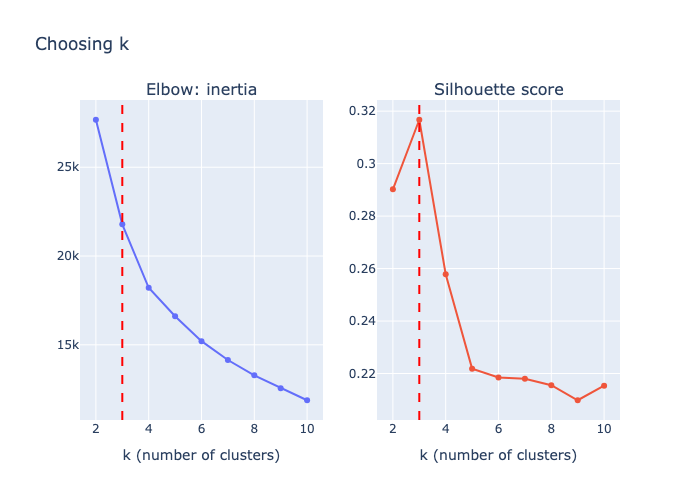

 k   inertia  silhouette
 2 27672.501       0.290
 3 21783.890       0.317
 4 18210.321       0.258
 5 16605.664       0.222
 6 15207.729       0.219
 7 14145.531       0.218
 8 13281.053       0.216
 9 12556.832       0.210
10 11878.795       0.215

Chosen k = 3 (silhouette 0.317, the highest among k >= 3).
Matches saved pipeline model: True


In [2]:
scores = evaluate_k(customers)
k = choose_k(scores)

fig = make_subplots(rows=1, cols=2, subplot_titles=("Elbow: inertia", "Silhouette score"))
fig.add_trace(go.Scatter(x=scores["k"], y=scores["inertia"], mode="lines+markers"), 1, 1)
fig.add_trace(go.Scatter(x=scores["k"], y=scores["silhouette"], mode="lines+markers"), 1, 2)
fig.add_vline(x=k, line_dash="dash", line_color="red")
fig.update_xaxes(title_text="k (number of clusters)")
fig.update_layout(showlegend=False, title="Choosing k")
fig.write_image(FIGURES_DIR / "elbow_silhouette.png", width=1100, height=450)
fig.show()
print(scores.round(3).to_string(index=False))
best = scores.loc[scores["k"] == k, "silhouette"].iloc[0]
print(f"\nChosen k = {k} (silhouette {best:.3f}, the highest among k >= {MIN_ACTIONABLE_K}).")
print("Matches saved pipeline model:", json.loads(CLUSTER_REPORT.read_text())["chosen_k"] == k)

## 2. Cluster profiles
Each cluster is auto-named by comparing its median recency, frequency and spend with the
median customer (e.g. "Recent · Frequent · High-spend").

In [3]:
profile = segment_summary(customers, by="cluster_name")
profile.style.format({"avg_recency_days": "{:.0f}", "avg_frequency": "{:.1f}", "avg_monetary": "{:,.0f}",
                      "total_revenue": "{:,.0f}", "revenue_share": "{:.1%}", "customer_share": "{:.1%}"})

,cluster_name,customers,avg_recency_days,avg_frequency,avg_monetary,total_revenue,revenue_share,customer_share
0,Cluster 2: Recent · Frequent · High-spend,2274,82,12.7,"10,060","22,875,872",87.9%,38.9%
1,Cluster 1: Lapsed · Occasional · Low-spend,2688,344,2.1,830,"2,230,977",8.6%,46.0%
2,Cluster 0: Recent · Occasional · Low-spend,877,65,2.1,"1,044","915,324",3.5%,15.0%


How do the algorithm's clusters line up with the rule-based RFM segments? (share of each cluster)

In [4]:
pd.crosstab(customers["cluster_name"], customers["segment"], normalize="index").round(2)

segment,At-risk,High-value,Inactive,Loyal,New,Regular
cluster_name,,,,,,
Cluster 0: Recent · Occasional · Low-spend,0.02,0.04,0.04,0.03,0.64,0.23
Cluster 1: Lapsed · Occasional · Low-spend,0.25,0.00,0.49,0.03,0.00,0.23
Cluster 2: Recent · Frequent · High-spend,0.13,0.53,0.00,0.22,0.00,0.12


## 3. Seeing the clusters with PCA
PCA finds the two directions that capture the most variation in the 7 scaled features.

PC1 explains 50.3%, PC2 22.2%; together 72.5% of the variance.


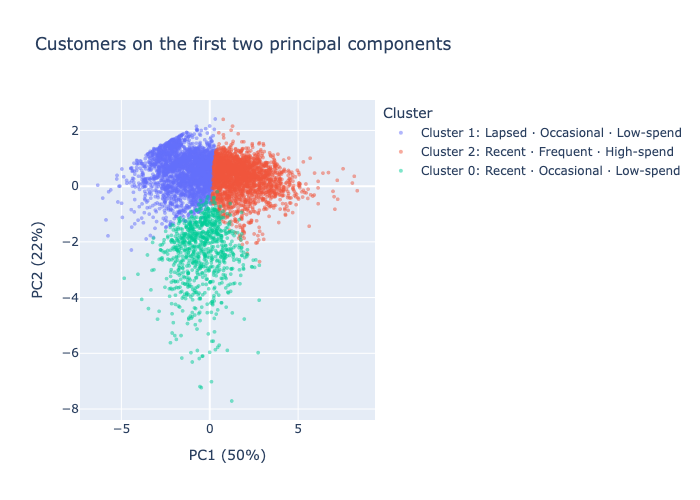

In [5]:
coords, explained = pca_projection(customers)
print(f"PC1 explains {explained[0]:.1%}, PC2 {explained[1]:.1%}; together {explained.sum():.1%} of the variance.")
fig = px.scatter(customers.assign(pc1=coords["pc1"], pc2=coords["pc2"]), x="pc1", y="pc2",
                 color="cluster_name", opacity=0.5,
                 title="Customers on the first two principal components",
                 labels={"pc1": f"PC1 ({explained[0]:.0%})", "pc2": f"PC2 ({explained[1]:.0%})",
                         "cluster_name": "Cluster"})
fig.update_traces(marker_size=4)
fig.write_image(FIGURES_DIR / "pca_clusters.png", width=1000, height=600)
fig.show()

## 4. What do the components mean? (loadings)
A loading is how much each original feature contributes to a component; sign shows direction.

In [6]:
loadings = pca_loadings(customers).round(2)
for pc in ["pc1", "pc2"]:
    top = loadings[pc].abs().nlargest(3).index.tolist()
    print(f"{pc.upper()} is driven most by: {', '.join(top)}")
loadings

PC1 is driven most by: monetary, frequency, unique_products
PC2 is driven most by: tenure_days, avg_days_between_orders, recency_days


,pc1,pc2
recency_days,-0.35,0.40
frequency,0.47,0.08
monetary,0.51,0.14
avg_order_value,0.30,0.15
unique_products,0.45,0.12
tenure_days,0.11,0.73
avg_days_between_orders,-0.30,0.50


## 5. Interpretation
- **PC1 = customer value/engagement:** frequency, spend and product variety load positively,
  recency and gaps between orders negatively, so customers further right are more valuable.
- **PC2 = customer age/lifecycle:** dominated by tenure (how long ago they first bought).
- The clusters separate mostly along PC1, giving a clear high-value group, a lapsed low-value
  group and a recent-but-occasional group, which map onto the RFM segments in the crosstab above.